# Track 1 · Steps 5–7: classification training (scratch, frozen, full fine-tuning)

AI251P Capstone, Phase 1 (M2–M3, reproducibility). Owner: Abdulmohsen Alharthi.

One notebook for all three models; pick the config in section 0 (`cls_scratch`, `cls_frozen`, `cls_full`). The three configs have the same keys and differ only in model and training length. Same seed(s), sampler, augmentation and **val-only model selection** for all.

What it adds to the Step 5 / Step 6 notebooks:
1. **Logit adjustment**: after training, a per-class bias on the logits is tuned on **val** macro-F1 (coordinate search). It is saved with the checkpoint and applied **unchanged** to test in Step 8, next to the raw result. Val numbers after adjustment are optimistic by construction; only the test numbers count.
2. **Fair comparison**: `img_sizes: [64, 96]` trains one run per size, for the table {scratch, frozen, full} × {64, 96}. Section 9 builds that table from all summaries.
3. **Stronger balance**: `balance_power` 0.75 (or any value); the run name and tags show it.
4. **Seeds**: `seeds: [42, 43, 44]` for the final model; the summary gives mean ± std per image size.
5. **Resume**: model, optimizer, scheduler, AMP scaler, history, RNG and W&B run id are saved every epoch. After a disconnect, re-run all cells: finished runs are skipped, an unfinished run continues from its last epoch in the same W&B run.
6. **Speed** (`gpu_aug: true`): crops are loaded into RAM and augmented on the GPU with the same recipe as Step 4 (random resized crop 75–100 %, aspect 0.9–1.1, horizontal flip, 90° rotations, brightness / contrast / saturation jitter). Differences from the CPU version: no hue jitter (±0.02 in Step 4), bilinear resampling. **Use the same `gpu_aug` setting for every run in the comparison table**; the Step 5 run (CPU aug, 64 px) is kept for reference, not mixed into the table.

Outputs per run (`<run>` = e.g. `cls-scratch-96-s42`):
- `02_Classification/Checkpoints/…_<run>_vN.pt` (best epoch + logit bias) and `Checkpoints/resume/<run>.pt`
- `02_Classification/…_ValPredictions_<run>_vN.csv.gz`, `…_ValConfusion_<run>_vN.csv/.png`, `…_Curves_<run>_vN.png`, `…_History_<run>_vN.csv`
- `02_Classification/…_Step{5,6,7}Summary_vN.json` and `…_ComparisonVal_vN.csv`

Runtime: **GPU** (T4).

## 0. Choose the config, install, mount Drive

In [29]:
CONFIG_NAME = 'cls_frozen'     # 'cls_scratch' (Step 5), 'cls_frozen' (Step 6), 'cls_full' (Step 7)
WANDB_MODE  = 'online'          # 'offline' logs locally (upload later with `wandb sync`)
!pip -q install wandb pyyaml
from google.colab import drive
drive.mount('/content/drive')
import os; os.makedirs('/content/configs', exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
%%writefile /content/configs/cls_scratch.yaml
# Track 1 classification config, Step 5 (cls-scratch). Same keys for cls_scratch / cls_frozen / cls_full.
# Temporary until the team repo config exists. Paths are relative to data_root.
run:
  name: cls-scratch
  tags: [cls-scratch, track1, phase1]
  wandb_project: ai251p-capstone
  wandb_entity: null          # null = your own W&B account; team entity when Rayan's project exists
seeds: [43, 44]                   # final selected model: [42, 43, 44] -> mean +- std
data:
  data_root: /content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial
  crops_dir: 01_Data/Processed/Crops
  crops_version: latest
  img_sizes: [64]         # one run per size (crops are stored at 96)
  balance_power: 0.5          # sampler weight 1/n_c**p: 0 none, 0.5 sqrt (Step 5), 0.75 stronger, 1 full balance
  gpu_aug: true               # crops in RAM + augmentation on the GPU (fast); false = CPU DataLoader as in Step 5
  num_workers: 2              # CPU DataLoader only
model:
  name: SmallCNN
  width: 32                   # channels of block 1, doubled per block (32-64-128-256)
  dropout: 0.3
train:
  epochs: 40
  batch_size: 256
  lr: 0.002
  backbone_lr_factor: 1.0     # unused for SmallCNN
  weight_decay: 0.0005
  warmup_epochs: 2
  early_stop_patience: 8
  label_smoothing: 0.05
  class_loss_boost: {truck: 1.0, bus: 1.0}   # extra CE weight on top of the sampler; 1.0 = off
  amp: true
  select_metric: val_macro_f1 # model chosen on VAL; test untouched until Step 8
  resume: true                # save model/optimizer/scheduler/scaler every epoch and continue after a disconnect
logit_adjust:
  enabled: true               # after training: per-class logit bias tuned on VAL macro-F1, applied unchanged to test in Step 8
  grid: [-2.0, 2.0, 0.1]      # bias range and step
  passes: 3
sanity:
  overfit_batch: 64
  overfit_steps: 300
output:
  dir: 02_Classification

Overwriting /content/configs/cls_scratch.yaml


In [31]:
%%writefile /content/configs/cls_frozen.yaml
# Track 1 classification config, Step 6 (cls-frozen). Same keys for cls_scratch / cls_frozen / cls_full.
# Temporary until the team repo config exists. Paths are relative to data_root.
run:
  name: cls-frozen
  tags: [cls-frozen, track1, phase1]
  wandb_project: ai251p-capstone
  wandb_entity: null          # null = your own W&B account; team entity when Rayan's project exists
seeds: [43, 44]                  # final selected model: [42, 43, 44] -> mean +- std
data:
  data_root: /content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial
  crops_dir: 01_Data/Processed/Crops
  crops_version: latest
  img_sizes: [64]
  balance_power: 0.5          # sampler weight 1/n_c**p: 0 none, 0.5 sqrt (Step 5), 0.75 stronger, 1 full balance
  gpu_aug: true               # crops in RAM + augmentation on the GPU (fast); false = CPU DataLoader as in Step 5
  num_workers: 2              # CPU DataLoader only
model:
  name: resnet18
  weights: IMAGENET1K_V1
  mode: frozen                # only the new head is trained; backbone and its BatchNorm fixed
  dropout: 0.2
train:
  epochs: 20
  batch_size: 256
  lr: 0.001
  backbone_lr_factor: 0.0     # frozen: backbone not trained
  weight_decay: 0.0001
  warmup_epochs: 1
  early_stop_patience: 5
  label_smoothing: 0.05
  class_loss_boost: {truck: 1.0, bus: 1.0}   # extra CE weight on top of the sampler; 1.0 = off
  amp: true
  select_metric: val_macro_f1 # model chosen on VAL; test untouched until Step 8
  resume: true                # save model/optimizer/scheduler/scaler every epoch and continue after a disconnect
logit_adjust:
  enabled: true               # after training: per-class logit bias tuned on VAL macro-F1, applied unchanged to test in Step 8
  grid: [-2.0, 2.0, 0.1]      # bias range and step
  passes: 3
sanity:
  overfit_batch: 64
  overfit_steps: 300
output:
  dir: 02_Classification

Overwriting /content/configs/cls_frozen.yaml


In [32]:
%%writefile /content/configs/cls_full.yaml
# Track 1 classification config, Step 7 (cls-full). Same keys for cls_scratch / cls_frozen / cls_full.
# Temporary until the team repo config exists. Paths are relative to data_root.
run:
  name: cls-full
  tags: [cls-full, track1, phase1]
  wandb_project: ai251p-capstone
  wandb_entity: null          # null = your own W&B account; team entity when Rayan's project exists
seeds: [43, 44]                   # final selected model: [42, 43, 44] -> mean +- std
data:
  data_root: /content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial
  crops_dir: 01_Data/Processed/Crops
  crops_version: latest
  img_sizes: [64]          # one run per size (crops are stored at 96)
  balance_power: 0.5          # sampler weight 1/n_c**p: 0 none, 0.5 sqrt (Step 5), 0.75 stronger, 1 full balance
  gpu_aug: true               # crops in RAM + augmentation on the GPU (fast); false = CPU DataLoader as in Step 5
  num_workers: 2              # CPU DataLoader only
model:
  name: resnet18
  weights: IMAGENET1K_V1
  mode: full                  # everything trained; backbone at lr * backbone_lr_factor
  dropout: 0.2
train:
  epochs: 25
  batch_size: 256
  lr: 0.001
  backbone_lr_factor: 0.1
  weight_decay: 0.0001
  warmup_epochs: 1
  early_stop_patience: 6
  label_smoothing: 0.05
  class_loss_boost: {truck: 1.0, bus: 1.0}   # extra CE weight on top of the sampler; 1.0 = off
  amp: true
  select_metric: val_macro_f1 # model chosen on VAL; test untouched until Step 8
  resume: true                # save model/optimizer/scheduler/scaler every epoch and continue after a disconnect
logit_adjust:
  enabled: true               # after training: per-class logit bias tuned on VAL macro-F1, applied unchanged to test in Step 8
  grid: [-2.0, 2.0, 0.1]      # bias range and step
  passes: 3
sanity:
  overfit_batch: 64
  overfit_steps: 300
output:
  dir: 02_Classification

Overwriting /content/configs/cls_full.yaml


In [33]:
%%writefile /content/aerial_crops.py
"""Aerial object crops for the AI251P 8-class classifier (Track 1).

Crops are stored by Step 4 as one uint8 array per split, shape (N, S, S, 3), plus an index CSV whose
`row` column points into the array. Labels follow CLASSES below.
"""
import numpy as np, pandas as pd, torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision.transforms import v2 as T

CLASSES = ['swimmer', 'boat', 'jetski', 'life_saving_appliances', 'buoy', 'car', 'truck', 'bus']
CLASS_TO_ID = {c: i for i, c in enumerate(CLASSES)}
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet, used for scratch and pretrained alike


class Rot90:
    """Random multiple of 90 degrees: aerial views have no fixed 'up'."""
    def __call__(self, x):
        return torch.rot90(x, int(torch.randint(4, (1,))), dims=(-2, -1))


def make_transforms(img_size, train):
    if train:
        return T.Compose([T.ToImage(), T.RandomResizedCrop(img_size, scale=(0.75, 1.0), ratio=(0.9, 1.1), antialias=True),
                          T.RandomHorizontalFlip(), Rot90(),
                          T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02),
                          T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)])
    return T.Compose([T.ToImage(), T.Resize(img_size, antialias=True),
                      T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)])


class CropDataset(Dataset):
    def __init__(self, array_path, index, transform=None):
        self.x = np.load(array_path, mmap_mode='r')
        self.index = index.sort_values('row').reset_index(drop=True)
        self.y = self.index.category.map(CLASS_TO_ID).to_numpy()
        assert len(self.index) == len(self.x) and not np.isnan(self.y.astype(float)).any()
        self.transform = transform

    def __len__(self): return len(self.index)

    def __getitem__(self, i):
        img = np.array(self.x[i])          # copy out of the read-only memmap
        if self.transform is not None: img = self.transform(img)
        return img, int(self.y[i])


def class_weights(labels, power=0.5):
    """w_c proportional to 1 / n_c**power, mean weight over samples = 1. power 0 = none, 1 = full balance."""
    n = np.bincount(labels, minlength=len(CLASSES)).astype(float)
    w = np.where(n > 0, 1.0 / np.maximum(n, 1) ** power, 0.0)
    return w / (w[labels].mean())


def seed_worker(worker_id):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s); import random; random.seed(s)


def make_loader(ds, batch_size, train, seed=42, balance_power=0.5, num_workers=2):
    g = torch.Generator().manual_seed(seed)
    sampler = None
    if train and balance_power > 0:
        w = class_weights(ds.y, balance_power)[ds.y]
        sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), num_samples=len(ds), replacement=True, generator=g)
    return DataLoader(ds, batch_size=batch_size, shuffle=train and sampler is None, sampler=sampler,
                      num_workers=num_workers, worker_init_fn=seed_worker, generator=g,
                      pin_memory=torch.cuda.is_available(), drop_last=train, persistent_workers=num_workers > 0)

Overwriting /content/aerial_crops.py


## 1. Load the config, seeds, output names

In [34]:
import sys, re, json, time, random, shutil, importlib, uuid
from pathlib import Path
import numpy as np, pandas as pd, yaml, torch, torch.nn as nn, torch.nn.functional as F, torchvision
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix, classification_report
sys.path.insert(0, '/content'); import aerial_crops as ac; importlib.reload(ac)
pd.set_option('display.width', 180)

CFG = yaml.safe_load(open(f'/content/configs/{CONFIG_NAME}.yaml'))
ROOT = Path(CFG['data']['data_root'])
CROP_DIR, OUT_DIR = ROOT / CFG['data']['crops_dir'], ROOT / CFG['output']['dir']
CKPT_DIR = OUT_DIR / 'Checkpoints'; RESUME_DIR = CKPT_DIR / 'resume'; RESUME_DIR.mkdir(parents=True, exist_ok=True)
RUN, MCFG, T = CFG['run']['name'], CFG['model'], CFG['train']
MODE = MCFG.get('mode', 'scratch')
STEP = {'scratch': 5, 'frozen': 6, 'full': 7}[MODE]
K = len(ac.CLASSES); LABELS = list(range(K))
DOMAIN = {c: ('sea' if i < 5 else 'urban') for i, c in enumerate(ac.CLASSES)}

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '(no GPU: Runtime -> Change runtime type)')
use_amp = T['amp'] and DEVICE == 'cuda'

TODAY = time.strftime('%Y-%m-%d')
_done = [int(m.group(1)) for f in os.listdir(OUT_DIR) if (m := re.match(rf'{TODAY}_Step{STEP}Summary_v(\d+)\.json$', f))]
VERSION = max(_done, default=0) + 1
def out_name(topic, ext): return f'{TODAY}_{topic}_v{VERSION}.{ext}'

def crop_file(topic, ext):
    want = CFG['data']['crops_version']; hits = []
    for f in os.listdir(CROP_DIR):
        m = re.match(rf'(\d{{4}}-\d{{2}}-\d{{2}})_{topic}_v(\d+)\.{re.escape(ext)}$', f)
        if m and (want == 'latest' or want == f'{m.group(1)}_v{m.group(2)}'): hits.append((m.group(1), int(m.group(2)), f))
    assert hits, f'no {topic} file in {CROP_DIR} for crops_version={want}'
    return CROP_DIR / max(hits)[2]
print(f'{CONFIG_NAME}: Step {STEP}, model {MCFG["name"]} ({MODE}), sizes {CFG["data"]["img_sizes"]}, seeds {CFG["seeds"]}, '
      f'balance_power {CFG["data"]["balance_power"]}, gpu_aug {CFG["data"]["gpu_aug"]} | output version {VERSION}')

device: cuda Tesla T4
cls_frozen: Step 6, model resnet18 (frozen), sizes [64], seeds [43, 44], balance_power 0.5, gpu_aug True | output version 2


## 2. Data: copy the crops to the local disk (and into RAM for `gpu_aug`)

In [35]:
index = pd.read_csv(crop_file('CropIndex', 'csv.gz'), keep_default_na=False)
CROPS_USED = {'index': crop_file('CropIndex', 'csv.gz').name}
local = {}
for s in ['train', 'val', 'test']:
    src = crop_file('Crops' + s.capitalize(), 'npy'); CROPS_USED[s] = src.name
    local[s] = f'/content/crops_{s}.npy'
    if not os.path.exists(local[s]) or os.path.getsize(local[s]) != os.path.getsize(src): shutil.copy(src, local[s])
assert len({re.match(r'(\d{4}-\d{2}-\d{2})_[A-Za-z]+_v(\d+)\.', v).groups() for v in CROPS_USED.values()}) == 1, \
    f'crop files from different Step 4 runs: {CROPS_USED}'
IDX = {s: index[index.split == s].sort_values('row').reset_index(drop=True) for s in ['train', 'val']}
Y = {s: torch.as_tensor(IDX[s].category.map(ac.CLASS_TO_ID).to_numpy()) for s in IDX}
RAM = {}
if CFG['data']['gpu_aug']:
    for s in IDX:
        t0 = time.time(); a = np.load(local[s]); assert len(a) == len(IDX[s])
        RAM[s] = torch.from_numpy(a); print(f'{s}: {tuple(a.shape)} in RAM ({a.nbytes / 1e9:.2f} GB, {time.time() - t0:.0f}s)')
print(CROPS_USED, {s: len(v) for s, v in IDX.items()}, '| test is not loaded here')

/tmp/ipykernel_521/927257369.py:1: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  index = pd.read_csv(crop_file('CropIndex', 'csv.gz'), keep_default_na=False)


train: (66925, 96, 96, 3) in RAM (1.85 GB, 2s)
val: (13800, 96, 96, 3) in RAM (0.38 GB, 1s)
{'index': '2026-10-20_CropIndex_v1.csv.gz', 'train': '2026-10-20_CropsTrain_v1.npy', 'val': '2026-10-20_CropsVal_v1.npy', 'test': '2026-10-20_CropsTest_v1.npy'} {'train': 66925, 'val': 13800} | test is not loaded here


## 3. Loaders

`gpu_aug: true`: batches are drawn from the in-RAM crops (same weighted sampler as Step 4: weight ∝ 1 / n_c^`balance_power`, with replacement, one epoch = len(train) draws), moved to the GPU as uint8 and augmented there. The sampler and the augmentation are re-seeded from (seed, epoch), so a resumed run sees the same batches it would have seen.

`gpu_aug: false`: the Step 4 / Step 5 CPU DataLoader.

GPU-aug loader: 13765 crops/s


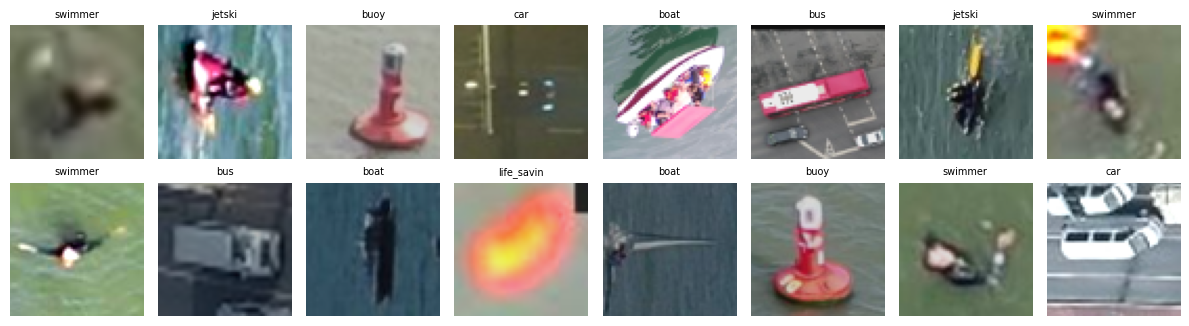

In [36]:
MEAN = torch.tensor(ac.MEAN).view(1, 3, 1, 1); STD = torch.tensor(ac.STD).view(1, 3, 1, 1)

def gpu_augment(x, out, gen):
    """x: uint8 (B, H, W, 3) on DEVICE -> normalised float (B, 3, out, out). Step 4 recipe without hue jitter."""
    B = x.shape[0]; x = x.permute(0, 3, 1, 2).float() / 255
    r = lambda lo, hi: torch.empty(B, device=x.device).uniform_(lo, hi, generator=gen)
    area, aspect = r(0.75, 1.0), torch.exp(r(np.log(0.9), np.log(1.1)))
    sw, sh = torch.sqrt(area * aspect).clamp(max=1), torch.sqrt(area / aspect).clamp(max=1)   # crop size, fraction of side
    tx, ty = (1 - sw) * r(-1, 1), (1 - sh) * r(-1, 1)
    theta = torch.zeros(B, 2, 3, device=x.device); theta[:, 0, 0], theta[:, 0, 2], theta[:, 1, 1], theta[:, 1, 2] = sw, tx, sh, ty
    x = F.grid_sample(x, F.affine_grid(theta, (B, 3, out, out), align_corners=False), mode='bilinear', align_corners=False)
    flip = torch.rand(B, device=x.device, generator=gen) < 0.5; x[flip] = x[flip].flip(-1)
    k = torch.randint(0, 4, (B,), device=x.device, generator=gen)
    for j in (1, 2, 3):
        m = k == j
        if m.any(): x[m] = torch.rot90(x[m], j, dims=(-2, -1))
    b, c, s = r(0.7, 1.3).view(B, 1, 1, 1), r(0.7, 1.3).view(B, 1, 1, 1), r(0.8, 1.2).view(B, 1, 1, 1)
    x = (x * b).clamp(0, 1)
    gray = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]).unsqueeze(1)
    x = ((x - gray.mean((2, 3), keepdim=True)) * c + gray.mean((2, 3), keepdim=True)).clamp(0, 1)
    gray = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]).unsqueeze(1)
    x = ((x - gray) * s + gray).clamp(0, 1)
    return (x - MEAN.to(x.device)) / STD.to(x.device)

def gpu_eval(x, out):
    x = x.permute(0, 3, 1, 2).float() / 255
    if x.shape[-1] != out: x = F.interpolate(x, size=(out, out), mode='bilinear', antialias=True, align_corners=False)
    return (x - MEAN.to(x.device)) / STD.to(x.device)

class RamLoader:
    """Batches from in-RAM uint8 crops; augmentation on the GPU. set_epoch() re-seeds sampler and augmentation."""
    def __init__(self, split, img, batch, train, seed):
        self.x, self.y, self.img, self.batch, self.train, self.seed = RAM[split], Y[split], img, batch, train, seed
        w = ac.class_weights(self.y.numpy(), CFG['data']['balance_power'])[self.y.numpy()]
        self.w = torch.as_tensor(w, dtype=torch.double); self.epoch = 0
    def set_epoch(self, e): self.epoch = e
    def __len__(self): return len(self.y) // self.batch if self.train else -(-len(self.y) // self.batch)
    def __iter__(self):
        if self.train:
            g = torch.Generator().manual_seed(self.seed * 1000 + self.epoch)
            order = (torch.multinomial(self.w, len(self.y), replacement=True, generator=g) if CFG['data']['balance_power'] > 0
                     else torch.randperm(len(self.y), generator=g))
            gg = torch.Generator(device=DEVICE).manual_seed(self.seed * 1000 + self.epoch)
        else: order = torch.arange(len(self.y))
        for i in range(len(self)):
            idx = order[i * self.batch:(i + 1) * self.batch]
            xb = self.x[idx].to(DEVICE, non_blocking=True); yb = self.y[idx].to(DEVICE, non_blocking=True)
            yield (gpu_augment(xb, self.img, gg) if self.train else gpu_eval(xb, self.img)), yb

class CpuLoader:
    def __init__(self, split, img, batch, train, seed):
        ds = ac.CropDataset(local[split], IDX[split], ac.make_transforms(img, train=train))
        self.dl = ac.make_loader(ds, batch, train=train, seed=seed, balance_power=CFG['data']['balance_power'],
                                 num_workers=CFG['data']['num_workers']); self.seed = seed
    def set_epoch(self, e):
        if self.dl.generator is not None: self.dl.generator.manual_seed(self.seed * 1000 + e)
    def __len__(self): return len(self.dl)
    def __iter__(self):
        for x, y in self.dl: yield x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)

def loaders(img, seed):
    L = RamLoader if CFG['data']['gpu_aug'] else CpuLoader
    return L('train', img, T['batch_size'], True, seed), L('val', img, 512, False, seed)

if CFG['data']['gpu_aug']:   # quick look and speed check
    tl, _ = loaders(CFG['data']['img_sizes'][-1], CFG['seeds'][0]); tl.set_epoch(1)
    t0 = time.time(); n = 0
    for i, (xb, yb) in enumerate(tl):
        n += len(yb)
        if i == 0: first = (xb[:16].cpu(), yb[:16].cpu())
        if i == 19: break
    if DEVICE == 'cuda': torch.cuda.synchronize()
    print(f'GPU-aug loader: {n / (time.time() - t0):.0f} crops/s')
    fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
    for a, im, lab in zip(axes.flat, *first):
        a.imshow((im * STD[0] + MEAN[0]).clamp(0, 1).permute(1, 2, 0)); a.set_title(ac.CLASSES[lab][:10], fontsize=7); a.axis('off')
    plt.tight_layout(); plt.show()

## 4. Models

In [37]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=8, width=32, dropout=0.3):
        super().__init__()
        layers, c_in = [], 3
        for i in range(4):
            c = width * 2 ** i
            layers += [nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                       nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.backbone = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, n_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    def forward(self, x): return self.head(self.backbone(x))

class Pretrained(nn.Module):
    def __init__(self, n_classes, weights, mode, dropout):
        super().__init__()
        net = torchvision.models.resnet18(weights=weights)
        self.backbone = nn.Sequential(*list(net.children())[:-1])
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(net.fc.in_features, n_classes))
        self.mode = mode
        if mode == 'frozen':
            for p in self.backbone.parameters(): p.requires_grad = False
    def train(self, on=True):
        super().train(on)
        if self.mode == 'frozen': self.backbone.eval()       # BatchNorm statistics stay fixed
        return self
    def forward(self, x): return self.head(self.backbone(x))

def build_model():
    if MCFG['name'] == 'SmallCNN': return SmallCNN(K, MCFG['width'], MCFG['dropout']).to(DEVICE)
    assert MCFG['name'] == 'resnet18'
    return Pretrained(K, MCFG['weights'], MCFG['mode'], MCFG['dropout']).to(DEVICE)
m = build_model()
N_PARAMS = sum(p.numel() for p in m.parameters()); N_TRAIN = sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f'{MCFG["name"]} ({MODE}): {N_PARAMS / 1e6:.2f} M parameters, {N_TRAIN / 1e6:.3f} M trainable'); del m

resnet18 (frozen): 11.18 M parameters, 0.004 M trainable


## 5. Sanity check: overfit one batch per image size

In [38]:
SANITY = {}
for img in CFG['data']['img_sizes']:
    set_seed(CFG['seeds'][0])
    ds = ac.CropDataset(local['train'], IDX['train'], ac.make_transforms(img, train=False))
    g = np.random.default_rng(CFG['seeds'][0])
    idx = np.concatenate([g.choice(np.flatnonzero(ds.y == c), min(8, (ds.y == c).sum()), replace=False)
                          for c in LABELS if (ds.y == c).any()])[:CFG['sanity']['overfit_batch']]
    xb = torch.stack([ds[i][0] for i in idx]).to(DEVICE); yb = torch.as_tensor(ds.y[idx]).to(DEVICE)
    m = build_model(); m.head[-2].p = 0.0; m.train()
    opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=1e-2 if MODE == 'frozen' else 1e-3)
    for step in range(CFG['sanity']['overfit_steps']):
        loss = F.cross_entropy(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad(): acc = (m(xb).argmax(1) == yb).float().mean().item()
    need = 0.90 if MODE == 'frozen' else 0.98      # a linear head on fixed features may not separate every crop
    print(f'{img}px, one batch of {len(idx)}: loss {loss.item():.4f}, accuracy {acc:.1%} after {step + 1} steps')
    assert acc >= need, f'the model cannot overfit one batch ({acc:.1%} < {need:.0%}): check labels, normalisation and the model'
    SANITY[img] = {'batch': int(len(idx)), 'steps': step + 1, 'final_loss': float(loss.item()), 'accuracy': acc}
    del m, opt

64px, one batch of 64: loss 0.0001, accuracy 100.0% after 300 steps


## 6. Metrics, logit adjustment, printed confusion matrix

In [39]:
@torch.no_grad()
def predict(model, dl):
    model.eval(); Lg, Ys = [], []
    for x, y in dl:
        with torch.autocast('cuda', enabled=use_amp): out = model(x)
        Lg.append(out.float().cpu()); Ys.append(y.cpu())
    Lg, Ys = torch.cat(Lg), torch.cat(Ys)
    return Lg.numpy(), Ys.numpy(), F.cross_entropy(Lg, Ys).item()

def softmax(L): e = np.exp(L - L.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def ece(P, Yv, bins=15):
    conf, pred = P.max(1), P.argmax(1); e = 0.0
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs((pred[m] == Yv[m]).mean() - conf[m].mean())
    return float(e)

def macro_f1_fast(Yv, pred):
    cm = np.bincount(Yv * K + pred, minlength=K * K).reshape(K, K); tp = np.diag(cm)
    p, r = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    return float(np.mean(np.where(p + r > 0, 2 * p * r / np.maximum(p + r, 1e-12), 0)))

def metrics(L, Yv, loss=None, prefix='val'):
    P = softmax(L); pred = P.argmax(1)
    rec = confusion_matrix(Yv, pred, labels=LABELS).diagonal() / np.maximum(np.bincount(Yv, minlength=K), 1)
    out = {f'{prefix}/acc': float((pred == Yv).mean()), f'{prefix}/ece': ece(P, Yv),
           f'{prefix}/macro_f1': float(f1_score(Yv, pred, labels=LABELS, average='macro', zero_division=0))}
    if loss is not None: out[f'{prefix}/loss'] = loss
    for dom in ('sea', 'urban'):
        ids = [i for i, c in enumerate(ac.CLASSES) if DOMAIN[c] == dom]
        out[f'{prefix}/macro_f1_{dom}'] = float(f1_score(Yv, pred, labels=ids, average='macro', zero_division=0))
    out.update({f'{prefix}_recall/{c}': float(r) for c, r in zip(ac.CLASSES, rec)})
    return out

def fit_logit_bias(L, Yv):
    """Per-class additive bias on the logits, coordinate search on val macro-F1. Mean bias is 0."""
    lo, hi, st = CFG['logit_adjust']['grid']; grid = np.round(np.arange(lo, hi + st / 2, st), 4)
    b = np.zeros(K); best = macro_f1_fast(Yv, L.argmax(1))
    for _ in range(CFG['logit_adjust']['passes']):
        changed = False
        for k in LABELS:
            for v in grid:
                b2 = b.copy(); b2[k] = v; s = macro_f1_fast(Yv, (L + b2).argmax(1))
                if s > best + 1e-9: best, b, changed = s, b2, True
        if not changed: break
    return b - b.mean()

def print_confusion(Yv, pred, title):
    cm = pd.DataFrame(confusion_matrix(Yv, pred, labels=LABELS), index=pd.Index(ac.CLASSES, name='true'),
                      columns=pd.Index(ac.CLASSES, name='predicted'))
    print(f'\n{title}: counts'); print(cm.to_string())
    print(f'\n{title}: row % (recall on the diagonal)'); print((cm.div(cm.sum(1).clip(lower=1), axis=0) * 100).round(1).to_string())
    off = cm.stack().rename('n').reset_index(); off = off[(off.true != off.predicted) & (off.n > 0)].sort_values('n', ascending=False)
    off['% of true class'] = (off.n / off.true.map(cm.sum(1)) * 100).round(1)
    print('\nlargest confusions:'); print(off.head(8).to_string(index=False))
    return cm

def save_confusion_png(cm, title, path):
    a = cm.to_numpy(); n = a / np.maximum(a.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7, 6)); ax.imshow(n, cmap='Blues', vmin=0, vmax=1)
    for i in LABELS:
        for j in LABELS: ax.text(j, i, a[i, j], ha='center', va='center', fontsize=7, color='white' if n[i, j] > .5 else 'black')
    ax.set_xticks(LABELS, ac.CLASSES, rotation=45, ha='right', fontsize=8); ax.set_yticks(LABELS, ac.CLASSES, fontsize=8)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(title, fontsize=9); plt.tight_layout()
    plt.savefig(path, dpi=130); plt.show()

## 7. Train every (image size, seed) with resume

Re-running this cell after a disconnect skips finished runs and continues unfinished ones from the last saved epoch. To start a run from scratch on purpose, delete its file in `Checkpoints/resume/`.

wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


/tmp/ipykernel_521/726119067.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


cls-frozen-64-s43 ep  1 | train loss 1.405 acc 0.572 | val loss 0.485 acc 0.854 macroF1 0.616 (sea 0.738, urban 0.412) truckR 0.17 busR 0.15 | 15s  *best*
cls-frozen-64-s43 ep  2 | train loss 0.710 acc 0.833 | val loss 0.433 acc 0.878 macroF1 0.662 (sea 0.793, urban 0.443) truckR 0.11 busR 0.33 | 8s  *best*
cls-frozen-64-s43 ep  3 | train loss 0.664 acc 0.851 | val loss 0.403 acc 0.888 macroF1 0.692 (sea 0.824, urban 0.471) truckR 0.20 busR 0.27 | 8s  *best*
cls-frozen-64-s43 ep  4 | train loss 0.652 acc 0.856 | val loss 0.388 acc 0.894 macroF1 0.700 (sea 0.836, urban 0.472) truckR 0.19 busR 0.24 | 8s  *best*
cls-frozen-64-s43 ep  5 | train loss 0.647 acc 0.857 | val loss 0.391 acc 0.885 macroF1 0.701 (sea 0.835, urban 0.478) truckR 0.33 busR 0.20 | 8s  *best*
cls-frozen-64-s43 ep  6 | train loss 0.646 acc 0.858 | val loss 0.405 acc 0.888 macroF1 0.698 (sea 0.832, urban 0.473) truckR 0.26 busR 0.22 | 8s
cls-frozen-64-s43 ep  7 | train loss 0.638 acc 0.862 | val loss 0.390 acc 0.893 mac

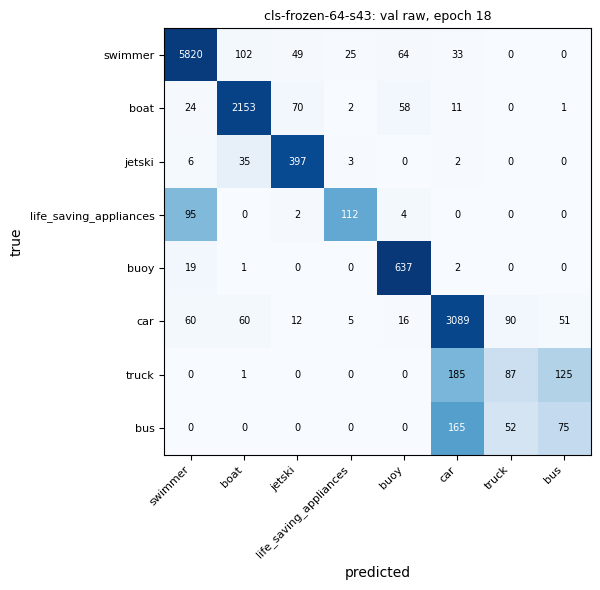

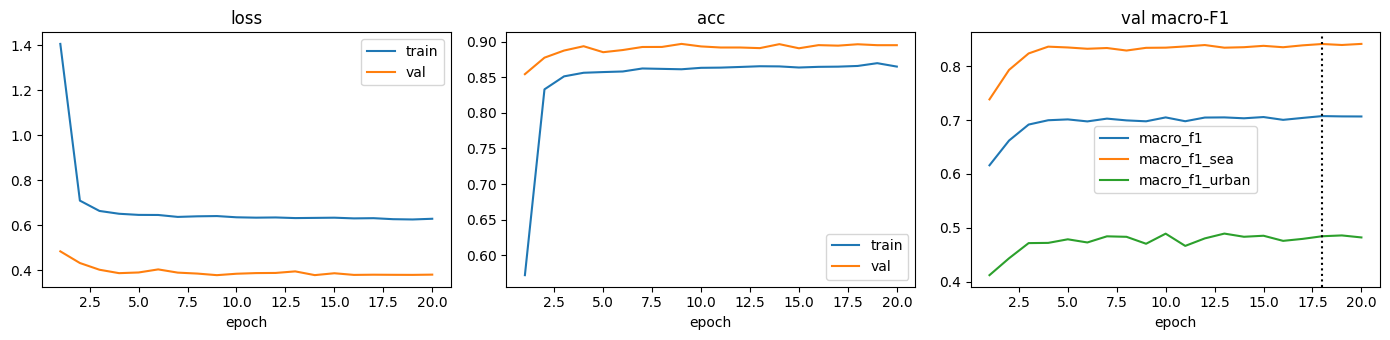

epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇███
epoch_time_s,█▁▁▁▁▁▁▁▁▁▁▂▂▁▁▁▁▁▁▁
lr,████▇▇▆▆▅▅▄▄▃▃▂▂▁▁▁▁
train/acc,▁▇██████████████████
train/loss,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/acc,▁▅▆▇▆▇▇▇█▇▇▇▇█▇█████
val/ece,█▇▇▃▂▆▃▁▃▃▃▂▆▂▄▃▄▅▄▅
val/loss,█▅▃▂▂▃▂▁▁▁▂▂▂▁▂▁▁▁▁▁
val/macro_f1,▁▅▇▇█▇█▇▇█▇████▇████
val/macro_f1_sea,▁▅▇██▇▇▇████████████
+9,...


/tmp/ipykernel_521/726119067.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


cls-frozen-64-s44 ep  1 | train loss 1.330 acc 0.596 | val loss 0.467 acc 0.863 macroF1 0.650 (sea 0.763, urban 0.463) truckR 0.26 busR 0.25 | 8s  *best*
cls-frozen-64-s44 ep  2 | train loss 0.701 acc 0.835 | val loss 0.420 acc 0.890 macroF1 0.694 (sea 0.820, urban 0.484) truckR 0.22 busR 0.22 | 8s  *best*
cls-frozen-64-s44 ep  3 | train loss 0.665 acc 0.851 | val loss 0.400 acc 0.889 macroF1 0.693 (sea 0.814, urban 0.493) truckR 0.32 busR 0.20 | 8s
cls-frozen-64-s44 ep  4 | train loss 0.648 acc 0.858 | val loss 0.387 acc 0.892 macroF1 0.690 (sea 0.825, urban 0.466) truckR 0.12 busR 0.35 | 8s
cls-frozen-64-s44 ep  5 | train loss 0.645 acc 0.859 | val loss 0.377 acc 0.898 macroF1 0.691 (sea 0.821, urban 0.475) truckR 0.22 busR 0.22 | 8s
cls-frozen-64-s44 ep  6 | train loss 0.645 acc 0.860 | val loss 0.401 acc 0.890 macroF1 0.685 (sea 0.820, urban 0.461) truckR 0.20 busR 0.24 | 8s
cls-frozen-64-s44 ep  7 | train loss 0.642 acc 0.862 | val loss 0.388 acc 0.895 macroF1 0.705 (sea 0.845, ur

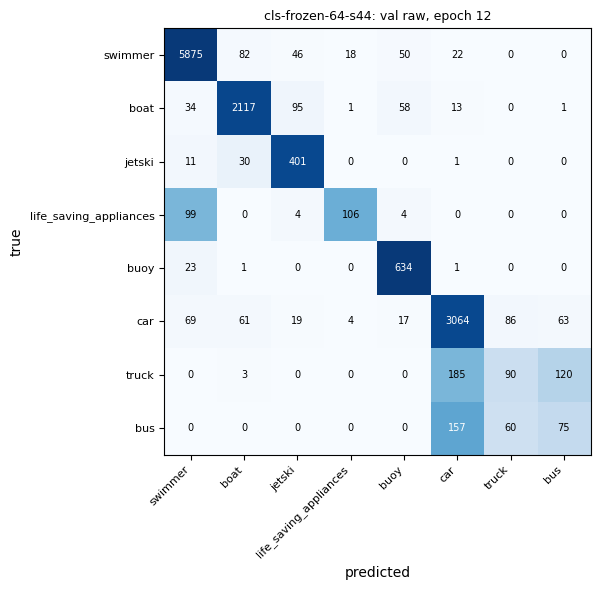

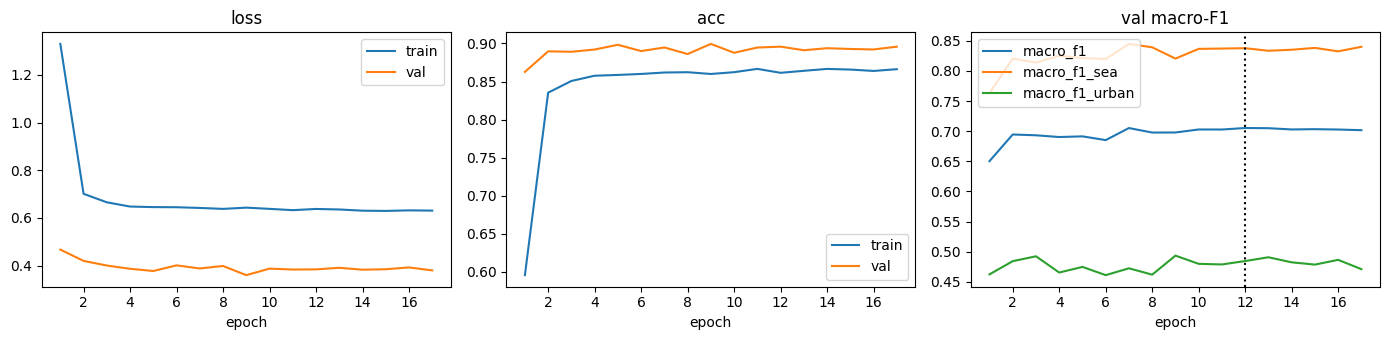

epoch,▁▁▂▂▃▃▄▄▅▅▅▆▆▇▇███
epoch_time_s,▄▁▆▃▅▃▅▃▇▂▅▄█▆▆▃▃
lr,████▇▇▆▆▅▅▄▃▃▂▂▁▁
train/acc,▁▇███████████████
train/loss,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/acc,▁▆▆▇█▆▇▅█▆▇▇▆▇▇▇▇
val/ece,█▇▃▃▂▃▄▄▁▂▃▄▄▃▄▅▃
val/loss,█▅▄▃▂▄▃▄▁▃▃▃▃▂▃▃▂
val/macro_f1,▁▇▆▆▆▅█▇▇████████
val/macro_f1_sea,▁▆▅▆▆▆██▆▇▇▇▇▇▇▇█
+9,...


In [40]:
from google.colab import userdata
os.environ['WANDB_API_KEY'] = userdata.get('WANDB_API_KEY')
import wandb
if WANDB_MODE == 'online': wandb.login()
boost = T.get('class_loss_boost') or {}
assert set(boost) <= set(ac.CLASSES), f'unknown class in class_loss_boost: {set(boost) - set(ac.CLASSES)}'
LOSS_W = torch.tensor([float(boost.get(c, 1.0)) for c in ac.CLASSES])
BOOSTED = {c: v for c, v in boost.items() if v != 1.0}
BP = CFG['data']['balance_power']

def run_name(img, seed):
    return (f'{RUN}-{img}-s{seed}' + (f'-bp{str(BP).replace(".", "")}' if BP != 0.5 else '') + ('-boost' if BOOSTED else '')
            + ('' if CFG['data']['gpu_aug'] else '-cpuaug'))

def rng_state():
    return {'py': random.getstate(), 'np': np.random.get_state(), 'torch': torch.get_rng_state(),
            'cuda': torch.cuda.get_rng_state_all() if DEVICE == 'cuda' else None}
def set_rng_state(s):
    random.setstate(s['py']); np.random.set_state(s['np']); torch.set_rng_state(s['torch'])
    if s['cuda'] is not None and DEVICE == 'cuda': torch.cuda.set_rng_state_all(s['cuda'])

def train_one(img, seed):
    name = run_name(img, seed); rfile = RESUME_DIR / f'{name}.pt'
    R = torch.load(rfile, map_location='cpu', weights_only=False) if (T['resume'] and rfile.exists()) else None
    if R is not None and R.get('done'):
        print(f'{name}: finished earlier, skipped (result loaded from {rfile.name})'); return R['result']
    train_dl, val_dl = loaders(img, seed)
    set_seed(seed); model = build_model()
    head = list(model.head.parameters()); back = [p for p in model.backbone.parameters() if p.requires_grad]
    groups = [{'params': head, 'lr': T['lr']}] + ([{'params': back, 'lr': T['lr'] * T['backbone_lr_factor']}] if back and MODE == 'full'
                                                 else [{'params': back, 'lr': T['lr']}] if back else [])
    opt = torch.optim.AdamW(groups, weight_decay=T['weight_decay'])
    steps = len(train_dl); total = T['epochs'] * steps; warm = max(1, T['warmup_epochs'] * steps)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                              0.5 * (1 + np.cos(np.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    crit = nn.CrossEntropyLoss(weight=LOSS_W.to(DEVICE), label_smoothing=T['label_smoothing'])
    key = f"val/{T['select_metric'].removeprefix('val_')}"
    st = {'epoch': 0, 'best': -1.0, 'best_epoch': -1, 'bad': 0, 'history': [], 'wandb_id': uuid.uuid4().hex[:12],
          'ckpt': str(CKPT_DIR / out_name(name, 'pt'))}
    if R is not None:
        model.load_state_dict(R['model']); opt.load_state_dict(R['opt']); sched.load_state_dict(R['sched'])
        scaler.load_state_dict(R['scaler']); set_rng_state(R['rng']); st = R['state']
        print(f"{name}: resuming after epoch {st['epoch']} (best {st['best']:.4f} at epoch {st['best_epoch']})")
    ckpt = Path(st['ckpt'])
    tags = list(CFG['run']['tags']) + [f'img{img}', f'seed{seed}', f'bp{BP}'] + (['loss-boost'] if BOOSTED else []) + \
           (['gpu-aug'] if CFG['data']['gpu_aug'] else ['cpu-aug'])
    wb = wandb.init(project=CFG['run']['wandb_project'], entity=CFG['run']['wandb_entity'], name=name, id=st['wandb_id'],
                    resume='allow', tags=tags, mode=WANDB_MODE, job_type='train', reinit=True,
                    config={**CFG, 'img_size': img, 'seed': seed, 'crops_used': CROPS_USED, 'n_params': N_PARAMS,
                            'n_trainable': N_TRAIN, 'sanity': SANITY[img], 'loss_boost': BOOSTED, 'step': STEP})
    wandb.define_metric('epoch'); wandb.define_metric('*', step_metric='epoch')

    for epoch in range(st['epoch'] + 1, T['epochs'] + 1):
        if st['bad'] >= T['early_stop_patience']: break
        train_dl.set_epoch(epoch); model.train(); t0 = time.time(); n = correct = 0; tl = 0.0
        for x, y in train_dl:
            with torch.autocast('cuda', enabled=use_amp):
                out = model(x); loss = crit(out, y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(y); n += len(y); correct += (out.argmax(1) == y).sum().item()
        Lv, Yv, vl = predict(model, val_dl)
        row = {'epoch': epoch, 'train/loss': tl / n, 'train/acc': correct / n, 'lr': opt.param_groups[0]['lr'],
               'epoch_time_s': time.time() - t0, **metrics(Lv, Yv, vl)}
        st['history'].append(row); wandb.log(row); flag = ''
        if row[key] > st['best']:
            st['best'], st['best_epoch'], st['bad'], flag = row[key], epoch, 0, '  *best*'
            torch.save({'model': model.state_dict(), 'config': CFG, 'img_size': img, 'seed': seed, 'classes': ac.CLASSES,
                        'epoch': epoch, 'val_macro_f1': st['best'], 'crops_used': CROPS_USED}, ckpt)
        else: st['bad'] += 1
        st['epoch'] = epoch
        torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                    'scaler': scaler.state_dict(), 'rng': rng_state(), 'state': st, 'done': False}, rfile)
        print(f"{name} ep {epoch:2d} | train loss {row['train/loss']:.3f} acc {row['train/acc']:.3f} | val loss {vl:.3f} "
              f"acc {row['val/acc']:.3f} macroF1 {row['val/macro_f1']:.3f} (sea {row['val/macro_f1_sea']:.3f}, "
              f"urban {row['val/macro_f1_urban']:.3f}) truckR {row['val_recall/truck']:.2f} busR {row['val_recall/bus']:.2f} "
              f"| {row['epoch_time_s']:.0f}s{flag}")
        if st['bad'] >= T['early_stop_patience']: print('early stop')

    # best epoch: raw and logit-adjusted results on val
    ck = torch.load(ckpt, map_location=DEVICE, weights_only=False); model.load_state_dict(ck['model'])
    Lv, Yv, vl = predict(model, val_dl); raw = metrics(Lv, Yv, vl)
    bias = fit_logit_bias(Lv, Yv) if CFG['logit_adjust']['enabled'] else np.zeros(K)
    adj = metrics(Lv + bias, Yv, prefix='val_adj')
    ck['logit_bias'] = bias.tolist(); torch.save(ck, ckpt)
    pred, pred_adj = Lv.argmax(1), (Lv + bias).argmax(1)
    print(f"\n{name}: best val macro-F1 {raw['val/macro_f1']:.4f} at epoch {st['best_epoch']}; "
          f"after logit adjustment {adj['val_adj/macro_f1']:.4f} (tuned on val, optimistic)")
    print('logit bias:', {c: round(float(v), 2) for c, v in zip(ac.CLASSES, bias)})
    print(classification_report(Yv, pred, labels=LABELS, target_names=ac.CLASSES, digits=3, zero_division=0))
    cm = print_confusion(Yv, pred, f'{name} val raw (epoch {st["best_epoch"]})')
    cma = print_confusion(Yv, pred_adj, f'{name} val logit-adjusted')
    cm.to_csv(OUT_DIR / out_name(f'ValConfusion_{name}', 'csv')); cma.to_csv(OUT_DIR / out_name(f'ValConfusionAdj_{name}', 'csv'))
    cm_png = OUT_DIR / out_name(f'ValConfusion_{name}', 'png')
    save_confusion_png(cm, f'{name}: val raw, epoch {st["best_epoch"]}', cm_png)

    vp = IDX['val'][['crop_id', 'dataset', 'category', 'source', 'box_side']].copy()
    P = softmax(Lv); vp['pred'] = [ac.CLASSES[k] for k in pred]; vp['pred_adj'] = [ac.CLASSES[k] for k in pred_adj]
    vp['conf'] = P.max(1)
    for i, c in enumerate(ac.CLASSES): vp[f'logit_{c}'] = Lv[:, i].round(4)
    vp.to_csv(OUT_DIR / out_name(f'ValPredictions_{name}', 'csv.gz'), index=False)

    H = pd.DataFrame(st['history']); H.to_csv(OUT_DIR / out_name(f'History_{name}', 'csv'), index=False)
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
    for k, a in (('loss', ax[0]), ('acc', ax[1])):
        a.plot(H.epoch, H[f'train/{k}'], label='train'); a.plot(H.epoch, H[f'val/{k}'], label='val'); a.set_title(k); a.legend()
    for k in ('val/macro_f1', 'val/macro_f1_sea', 'val/macro_f1_urban'): ax[2].plot(H.epoch, H[k], label=k.split('/')[1])
    ax[2].axvline(st['best_epoch'], color='k', ls=':'); ax[2].set_title('val macro-F1'); ax[2].legend()
    for a in ax: a.set_xlabel('epoch')
    plt.tight_layout(); plt.savefig(OUT_DIR / out_name(f'Curves_{name}', 'png'), dpi=120); plt.show()

    wandb.log({'val/confusion_matrix': wandb.plot.confusion_matrix(y_true=Yv, preds=pred, class_names=ac.CLASSES),
               'val/confusion_png': wandb.Image(str(cm_png))})
    wandb.summary.update({'best_epoch': st['best_epoch'], **{f'best/{k}': v for k, v in raw.items()},
                          **{f'best/{k}': v for k, v in adj.items()}, 'logit_bias': dict(zip(ac.CLASSES, bias.tolist()))})
    art = wandb.Artifact(f'{name}-model', type='model', metadata={'val_macro_f1': st['best'], 'epoch': st['best_epoch'], 'img_size': img})
    art.add_file(str(ckpt)); wb.log_artifact(art)
    url = wb.url; wandb.finish()
    result = {'run': name, 'model': MCFG['name'], 'mode': MODE, 'img_size': img, 'seed': seed, 'balance_power': BP,
              'loss_boost': BOOSTED, 'gpu_aug': CFG['data']['gpu_aug'], 'wandb_url': url, 'best_epoch': st['best_epoch'],
              'epochs_run': int(H.epoch.max()), 'mean_epoch_s': float(H.epoch_time_s.mean()), 'checkpoint': ckpt.name,
              'val_raw': raw, 'val_adjusted': adj, 'logit_bias': dict(zip(ac.CLASSES, bias.tolist()))}
    torch.save({'done': True, 'result': result, 'state': st}, rfile)     # small file: weights are in the checkpoint
    return result

RESULTS = [train_one(img, seed) for img in CFG['data']['img_sizes'] for seed in CFG['seeds']]

## 8. Summary of this config (mean ± std over seeds)

In [41]:
rows = [{'run': r['run'], 'img_size': r['img_size'], 'seed': r['seed'],
         **{f'raw {k.split("/")[-1]}': v for k, v in r['val_raw'].items() if k.startswith('val/') or 'recall' in k},
         'adj macro_f1': r['val_adjusted']['val_adj/macro_f1']} for r in RESULTS]
R = pd.DataFrame(rows)
cols = ['raw macro_f1', 'adj macro_f1', 'raw macro_f1_sea', 'raw macro_f1_urban', 'raw acc', 'raw ece', 'raw truck', 'raw bus']
agg = R.groupby('img_size')[cols].agg(['mean', 'std', 'count']).round(4)
print('val only (test is evaluated once in Step 8):'); print(agg.to_string())
SUMMARY = {'step': STEP, 'config_name': CONFIG_NAME, 'mode': MODE, 'created': time.strftime('%Y-%m-%d %H:%M'), 'version': VERSION,
           'config': CFG, 'crops_used': CROPS_USED, 'device': DEVICE, 'n_params': N_PARAMS, 'n_trainable': N_TRAIN,
           'sanity_overfit': SANITY, 'runs': RESULTS,
           'mean_std_by_img_size': {str(k): {f'{c}': {'mean': float(agg.loc[k, (c, 'mean')]),
                                                      'std': None if pd.isna(agg.loc[k, (c, 'std')]) else float(agg.loc[k, (c, 'std')]),
                                                      'n_seeds': int(agg.loc[k, (c, 'count')])} for c in cols} for k in agg.index},
           'test': 'not evaluated (Step 8)'}
out = OUT_DIR / out_name(f'Step{STEP}Summary', 'json')
json.dump(SUMMARY, open(out, 'w'), indent=2, default=float); print('saved', out)

val only (test is evaluated once in Step 8):
         raw macro_f1               adj macro_f1               raw macro_f1_sea               raw macro_f1_urban               raw acc               raw ece               raw truck               raw bus           
                 mean     std count         mean     std count             mean     std count               mean     std count    mean     std count    mean     std count      mean     std count    mean  std count
img_size                                                                                                                                                                                                             
64             0.7063  0.0015     2       0.7199  0.0034     2           0.8395  0.0027     2             0.4844  0.0003     2  0.8961  0.0004     2  0.0662  0.0015     2    0.2224  0.0053     2  0.2568  0.0     2
saved /content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial/02_Classification/2026-10-23_Step6Su

## 9. Comparison table across all configs run so far (val)

Reads every `…_Step{5,6,7}Summary_vN.json` written by this notebook and builds {scratch, frozen, full} × {64, 96}, mean ± std over seeds, raw and logit-adjusted. Runs with a different `balance_power`, loss boost or augmentation are listed as separate rows. The original Step 5 run (CPU augmentation, written by the Step 5 notebook) is shown at the bottom for reference only.